# ARTI 403 – Image Processing
## Lab 9 — Morphological Operations

**Student name:** Ahmed Albuainain
**Student ID:** 2240006128
**Section:** 7MA1
**Date:** 11 November 2026

---

### Objective
Apply morphological image processing techniques — erosion, dilation, opening and closing —
to a new image, and investigate how the shape and size of the structuring element affect the
result.

### Contents
| Part | Description |
|---|---|
| Part 0 | Environment check, the image, and getting the polarity right |
| Part 1 | What erosion and dilation actually do |
| Task 1 | Erosion, dilation, opening and closing on the Balls image |
| Task 2 | Structuring element shapes and sizes compared |

---
## Part 0 — Environment check and the image

The task asks for a different binary image and suggests **Balls**. That image is a good choice
for morphology because it contains exactly the features these operations are designed to act on:

* **Touching objects** — the balls are stacked in a pyramid and share boundaries, so erosion
  should be able to separate them.
* **Holes inside the objects** — each ball carries a white circle with its number, which becomes
  an enclosed hole once the balls are the foreground. Closing should fill these.
* **Small detached marks** — the digits themselves become small separate shapes, which is what
  opening is supposed to remove.

In [1]:
import os
import sys
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Python :", sys.version.split()[0])
print("NumPy  :", np.__version__)
print("OpenCV :", cv2.__version__)

%matplotlib inline

Python : 3.13.5
NumPy  : 2.3.5
OpenCV : 5.0.0


In [2]:
SEARCH_DIRS = [".", "images", os.path.join("..", "images")]

def find_image(*names):
    for name in names:
        for d in SEARCH_DIRS:
            p = os.path.join(d, name)
            if os.path.exists(p):
                return p
    for d in SEARCH_DIRS:
        hits = sorted(glob.glob(os.path.join(d, "*.jpg")) + glob.glob(os.path.join(d, "*.png")))
        if hits:
            return hits[0]
    raise FileNotFoundError("no image file found next to the notebook or in images/")


os.makedirs("output", exist_ok=True)

imgFile = find_image("Balls.png", "Balls.jpg", "balls.png")
print("using:", os.path.abspath(imgFile))

raw = cv2.imread(imgFile, 0)
print("original size:", raw.shape)

using: c:\Users\ahmad\OneDrive\Desktop\im Labs\lab1\Lab 9\Balls.png
original size: (1234, 1274)


### Resizing, and why

The original is about 1270 pixels wide. Task 2 requires structuring elements of 3x3, 5x5 and
7x7 — on an image that size a 7x7 element spans about half a percent of the width, so all three
would produce changes too small to see or to tell apart.

The image is therefore resized to roughly 460 pixels wide. The required element sizes then
cover a meaningful fraction of a ball, and the comparison the task asks for becomes visible.
`INTER_AREA` is used because it is the correct interpolation for shrinking.

In [3]:
h, w = raw.shape
scale = 460 / w
img = cv2.resize(raw, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
print("working size :", img.shape)

working size : (445, 460)


### Getting the polarity right

This is the step that decides whether every result below is meaningful or backwards.

**OpenCV's morphological operations treat white (255) as the object and black (0) as the
background.** Erosion shrinks white, dilation grows white — always, regardless of what the
picture shows.

In this image the balls are **dark** on a **light** background. A plain
`cv2.THRESH_BINARY + THRESH_OTSU`, which is what the lab notebook uses, therefore makes the
*background* white and the balls black. Erosion would then eat away at the background, which
makes the balls appear to **grow** — the exact opposite of what erosion does.

In [4]:
_, binary_plain = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

print("THRESH_BINARY     -> white covers", f"{100 * (binary_plain > 0).mean():.1f}%",
      "of the image  (this is the background)")
print("THRESH_BINARY_INV -> white covers", f"{100 * (binary > 0).mean():.1f}%",
      "of the image  (these are the balls)")

k = np.ones((7, 7), np.uint8)
print()
print("the same erosion applied to each:")
print("  on THRESH_BINARY     : white goes to",
      f"{100 * (cv2.erode(binary_plain, k) > 0).mean():.1f}%  <- the balls LOOK bigger")
print("  on THRESH_BINARY_INV : white goes to",
      f"{100 * (cv2.erode(binary, k) > 0).mean():.1f}%  <- the balls shrink, as erosion should")

THRESH_BINARY     -> white covers 68.2% of the image  (this is the background)
THRESH_BINARY_INV -> white covers 31.8% of the image  (these are the balls)

the same erosion applied to each:
  on THRESH_BINARY     : white goes to 51.8%  <- the balls LOOK bigger
  on THRESH_BINARY_INV : white goes to 16.2%  <- the balls shrink, as erosion should


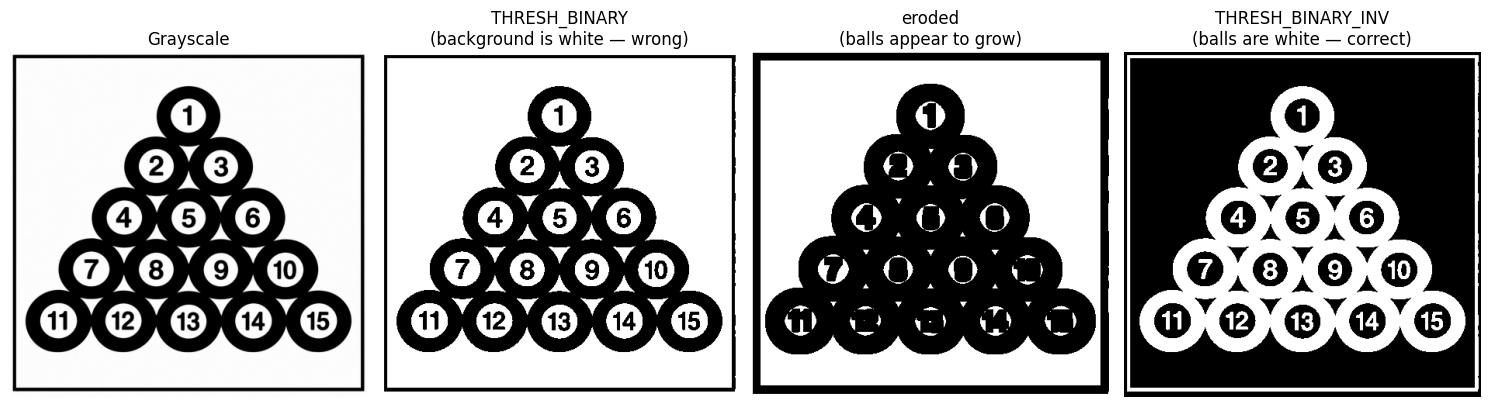

In [5]:
plt.figure(figsize=(15, 4.6))
plt.subplot(141), plt.imshow(img, cmap='gray'), plt.title('Grayscale'), plt.axis('off')
plt.subplot(142), plt.imshow(binary_plain, cmap='gray')
plt.title('THRESH_BINARY\n(background is white — wrong)'), plt.axis('off')
plt.subplot(143), plt.imshow(cv2.erode(binary_plain, k), cmap='gray')
plt.title('eroded\n(balls appear to grow)'), plt.axis('off')
plt.subplot(144), plt.imshow(binary, cmap='gray')
plt.title('THRESH_BINARY_INV\n(balls are white — correct)'), plt.axis('off')
plt.tight_layout()
plt.show()

The third panel makes the point: nothing is wrong with the erosion, it did exactly what
erosion does. It is the **assignment of foreground and background** that was wrong. Every
operation from here on uses `binary`, where the balls are white.

---
## Part 1 — What erosion and dilation actually do

Both operations slide a **structuring element** over the image and ask a question at every
position:

* **Erosion** — keep this pixel only if the structuring element fits **entirely inside** the
  object. Anything thinner than the element disappears, so objects shrink, thin connections
  break, and small marks vanish.
* **Dilation** — keep this pixel if the structuring element touches the object **anywhere**.
  Objects grow, gaps close, and nearby shapes merge.

Everything else in this lab is built from these two. **Opening** is erosion followed by
dilation, **closing** is dilation followed by erosion, and the ordering is what gives each its
character.

### The two are duals

Eroding the object is the same as dilating the background and taking the complement. This is
worth checking rather than taking on faith, since it explains why the polarity mistake in
Part 0 produced the result it did.

In [6]:
kernel = np.ones((5, 5), np.uint8)

eroded_fg = cv2.erode(binary, kernel)
dilated_bg = cv2.bitwise_not(cv2.dilate(cv2.bitwise_not(binary), kernel))

print("erode(object) vs not(dilate(not(object))) — identical:",
      np.array_equal(eroded_fg, dilated_bg))
print()
print("so an erosion that looks like it is growing the objects is simply a dilation")
print("of whatever the code has labelled as background.")

erode(object) vs not(dilate(not(object))) — identical: True

so an erosion that looks like it is growing the objects is simply a dilation
of whatever the code has labelled as background.


---
# Task 1 — The four operations applied to the Balls image

A 7x7 elliptical structuring element is used throughout this task so that the four results are
directly comparable. The shapes and sizes themselves are varied in Task 2.

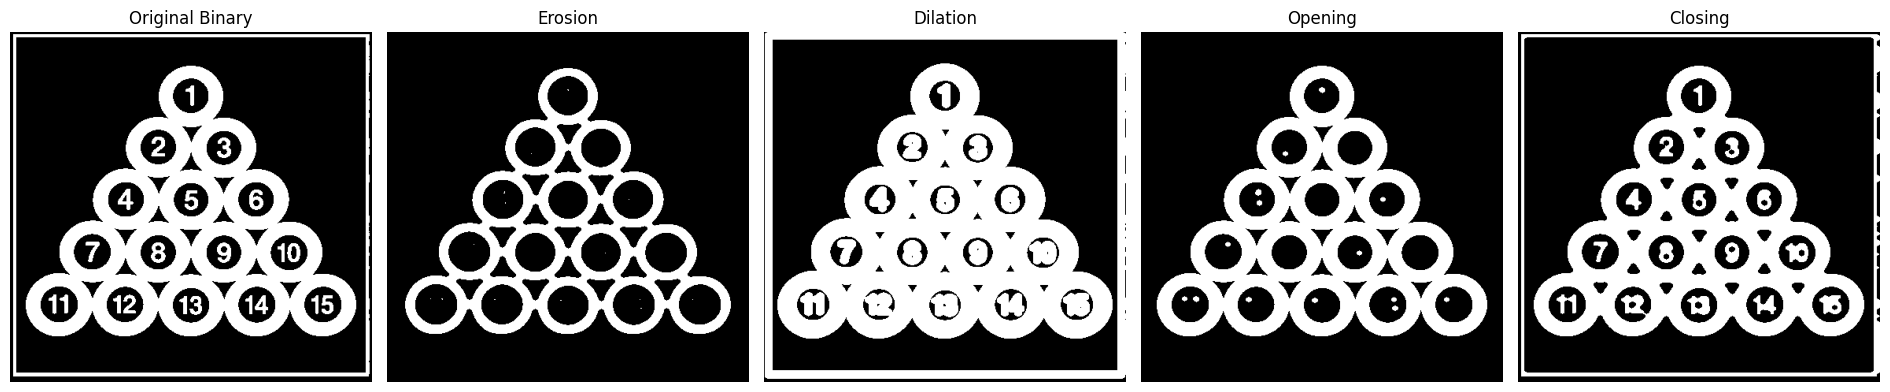

In [7]:
se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))

erosion = cv2.erode(binary, se, iterations=1)
dilation = cv2.dilate(binary, se, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, se)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, se)

fig, axes = plt.subplots(1, 5, figsize=(19, 4.4))
for ax, im, t in zip(axes,
                     [binary, erosion, dilation, opening, closing],
                     ['Original Binary', 'Erosion', 'Dilation', 'Opening', 'Closing']):
    ax.imshow(im, cmap='gray')
    ax.set_title(t, fontsize=12)
    ax.axis('off')
plt.tight_layout()
plt.savefig('output/lab9_task1.png', dpi=110, bbox_inches='tight')
plt.show()

In [8]:
def white_pct(im):
    return 100 * (im > 0).mean()

print(f"{'operation':<20}{'white area':>12}{'change':>12}")
print("-" * 44)
base = white_pct(binary)
print(f"{'original':<20}{base:>11.2f}%{'—':>12}")
for name, im in [('erosion', erosion), ('dilation', dilation),
                 ('opening', opening), ('closing', closing)]:
    print(f"{name:<20}{white_pct(im):>11.2f}%{white_pct(im) - base:>+11.2f}%")

operation             white area      change
--------------------------------------------
original                  31.85%           —
erosion                   18.45%     -13.39%
dilation                  46.21%     +14.36%
opening                   26.28%      -5.57%
closing                   33.13%      +1.29%


### Erosion and dilation — the obvious pair

Erosion removed about 13% of the image area and dilation added about 14%. Everything the balls
lost, the background gained, which is the duality from Part 1 showing up as a number.

### Opening and closing — the interesting pair

Notice that opening and closing barely changed the total area at all, a few percent each way,
while erosion and dilation changed it enormously. That is the whole point of combining the two
operations: the second step undoes the size change caused by the first, leaving only the
**structural** effect.

The two sections below show what that structural effect actually is.

## 1.1 Opening removes small objects without shrinking large ones

Opening erodes and then dilates. Anything thin enough to vanish during the erosion is gone for
good — the dilation cannot bring back what no longer exists. Anything that survived is restored
to roughly its original size.

In this image the digits printed on the balls are the small objects. The claim is that opening
removes them while leaving the balls themselves untouched, and it can be checked exactly:
measure the largest connected component, which is the mass of balls, separately from everything
else.

In [9]:
def component_split(im):
    """Area of the largest white component, and the total area of all the others."""
    n, _, stats, _ = cv2.connectedComponentsWithStats((im > 0).astype(np.uint8))
    areas = sorted(stats[1:, cv2.CC_STAT_AREA], reverse=True)
    return (areas[0] if areas else 0), int(sum(areas[1:])), len(areas)


big0, small0, n0 = component_split(binary)
print(f"original : largest component {big0:>6} px | all other components {small0:>6} px"
      f" | {n0} components")
print()
for size in [3, 5, 7, 9]:
    s = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
    big, small, _ = component_split(cv2.morphologyEx(binary, cv2.MORPH_OPEN, s))
    print(f"open {size}x{size} : largest kept {100 * big / big0:>6.1f}%"
          f" | small objects kept {100 * small / small0:>6.1f}%")

original : largest component  53259 px | all other components  11932 px | 23 components

open 3x3 : largest kept  100.0% | small objects kept   99.4%
open 5x5 : largest kept  100.0% | small objects kept   56.5%
open 7x7 : largest kept  100.0% | small objects kept    4.5%
open 9x9 : largest kept  100.0% | small objects kept    0.0%


The result is as clean as the theory predicts. At 7x7 the largest component retains
**100.0%** of its area — not approximately, exactly — while the small objects are reduced to
**4.5%** of theirs. Opening is a size filter: below the threshold set by the structuring
element, objects are deleted; above it, they are left alone.

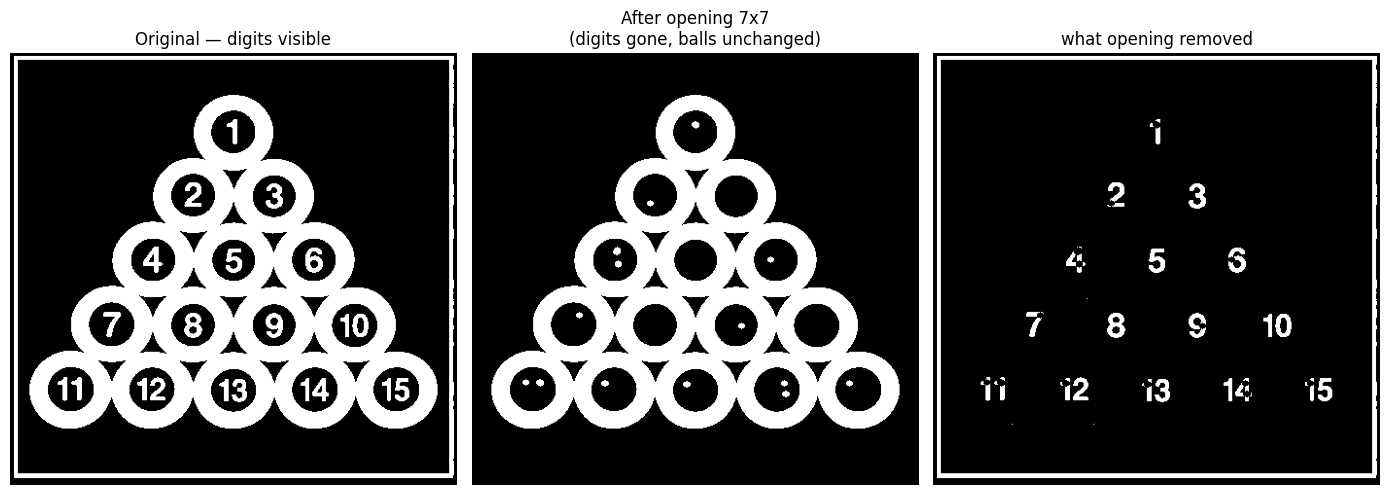

In [10]:
s7 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
plt.figure(figsize=(14, 4.8))
plt.subplot(131), plt.imshow(binary, cmap='gray')
plt.title('Original — digits visible'), plt.axis('off')
plt.subplot(132), plt.imshow(cv2.morphologyEx(binary, cv2.MORPH_OPEN, s7), cmap='gray')
plt.title('After opening 7x7\n(digits gone, balls unchanged)'), plt.axis('off')
plt.subplot(133), plt.imshow(cv2.absdiff(binary, cv2.morphologyEx(binary, cv2.MORPH_OPEN, s7)),
                             cmap='gray')
plt.title('what opening removed'), plt.axis('off')
plt.tight_layout()
plt.show()

## 1.2 Closing fills holes — up to a point

Closing dilates and then erodes. A hole small enough to be sealed shut by the dilation cannot
be reopened by the erosion, so it is filled permanently; the outer boundary, meanwhile, grows
and then shrinks back to where it started.

The white circles carrying the numbers are enclosed holes in the ball shapes, so closing should
fill them. Measuring the total area of enclosed holes tests this directly.

In [11]:
def hole_stats(im):
    """Count and area of enclosed background regions (the outer background is excluded)."""
    n, _, stats, _ = cv2.connectedComponentsWithStats((im == 0).astype(np.uint8))
    areas = [stats[i, cv2.CC_STAT_AREA] for i in range(1, n)
             if stats[i, cv2.CC_STAT_AREA] < 0.4 * im.size]
    return len(areas), int(sum(areas)), (max(areas) if areas else 0)


print(f"{'kernel':<10}{'white area':>12}{'holes':>8}{'hole area':>12}{'largest hole':>14}")
print("-" * 58)
n_, a_, m_ = hole_stats(binary)
print(f"{'original':<10}{white_pct(binary):>11.2f}%{n_:>8}{a_:>12}{m_:>14}")
for size in [5, 7, 9, 11, 13, 15]:
    s = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
    c = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, s)
    n_, a_, m_ = hole_stats(c)
    print(f"{f'{size}x{size}':<10}{white_pct(c):>11.2f}%{n_:>8}{a_:>12}{m_:>14}")

kernel      white area   holes   hole area  largest hole
----------------------------------------------------------
original        31.85%      39       31320          8316
5x5             32.39%      44       30361          8307
7x7             33.13%      51       28918          6816
9x9             36.18%      44       22803          3238
11x11           39.02%      57       17112          3230
13x13           42.01%      32       35842         24546
15x15           45.53%      19       28863         24349


### The hole area reverses direction, and the reason is worth understanding

Up to 11x11 the measurement behaves exactly as expected: the total hole area falls steadily
from 31,320 pixels to 17,112 as larger and larger holes get sealed.

At 13x13 it jumps back up to 35,842 — **higher than the original image**. That looks like a
failure of the method, but the last column explains it. The largest single hole leaps from
3,230 pixels to 24,546: one enormous new hole has appeared that was not there before.

What happened is that the structuring element finally became large enough to bridge the gaps
**between** neighbouring balls. Once adjacent balls merge into one shape, the triangular gaps
between them stop being part of the outer background and become enclosed holes in their own
right. Closing did not fail — it filled the holes it was asked to fill, and in doing so created
new ones at a larger scale.

The practical lesson is that the structuring element must be chosen relative to **both** the
features being removed and the spacing between objects. Too large and the operation starts
acting on a structure it was never aimed at.

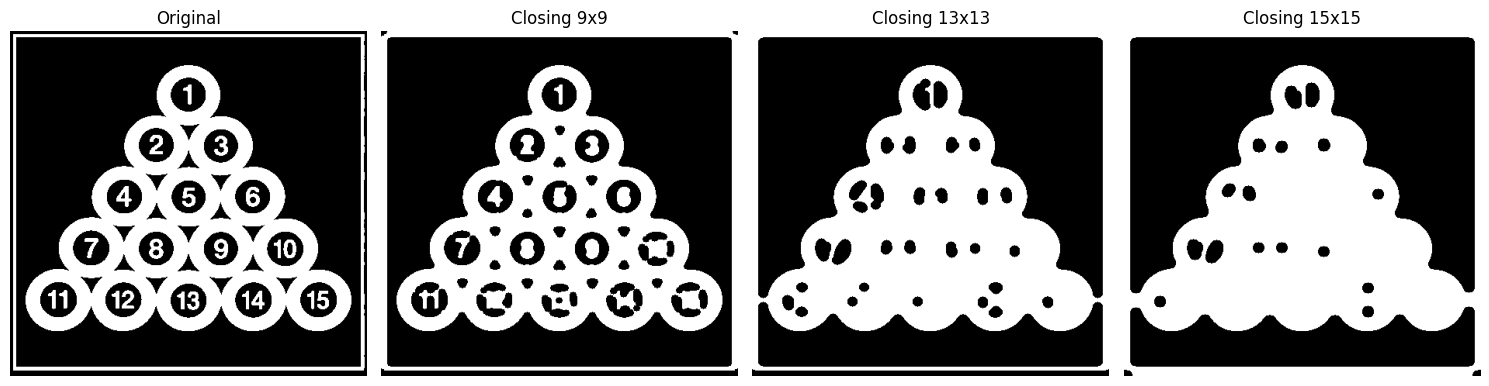

In [12]:
plt.figure(figsize=(15, 4.6))
for i, size in enumerate([0, 9, 13, 15]):
    plt.subplot(1, 4, i + 1)
    if size == 0:
        plt.imshow(binary, cmap='gray'), plt.title('Original')
    else:
        s = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
        plt.imshow(cv2.morphologyEx(binary, cv2.MORPH_CLOSE, s), cmap='gray')
        plt.title(f'Closing {size}x{size}')
    plt.axis('off')
plt.tight_layout()
plt.show()

## 1.3 Erosion separates touching objects

One more property worth demonstrating, because it is the usual reason erosion is applied to an
image like this one. The balls in the pyramid touch, so a connected-component analysis counts
them as a single blob. Eroding shrinks each ball away from its neighbours and breaks those
contacts.

In [13]:
def largest_area(im):
    n, _, stats, _ = cv2.connectedComponentsWithStats((im > 0).astype(np.uint8))
    return max(stats[1:, cv2.CC_STAT_AREA]) if n > 1 else 0

print("area of the single largest connected blob, as erosion is increased:")
print()
print(f"{'kernel':<10}{'largest blob':>14}{'% of original':>16}")
print("-" * 40)
base_blob = largest_area(binary)
print(f"{'original':<10}{base_blob:>14}{100.0:>15.1f}%")
for size in [5, 9, 13, 17]:
    s = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
    a = largest_area(cv2.erode(binary, s))
    print(f"{f'{size}x{size}':<10}{a:>14}{100 * a / base_blob:>15.1f}%")

area of the single largest connected blob, as erosion is increased:

kernel      largest blob   % of original
----------------------------------------
original           53259          100.0%
5x5                42611           80.0%
9x9                31612           59.4%
13x13              20335           38.2%
17x17               5812           10.9%


---
# Task 2 — Structuring element shapes and sizes

The task asks for three shapes — square, cross and ellipse — at three sizes, 3x3, 5x5 and 7x7.

`cv2.getStructuringElement` builds all three. The important thing to notice is that the name
describes the shape but what actually matters is **how many pixels the element contains**,
since that is what determines how much of an object must be present for it to survive erosion.

In [14]:
shapes = [('Square (RECT)', cv2.MORPH_RECT),
          ('Cross', cv2.MORPH_CROSS),
          ('Ellipse', cv2.MORPH_ELLIPSE)]
sizes = [3, 5, 7]

for size in sizes:
    print(f"--- {size}x{size} ---")
    for name, flag in shapes:
        se_ = cv2.getStructuringElement(flag, (size, size))
        print(f"{name:<16} {int(se_.sum()):>2} pixels")
        print(se_)
    print()

--- 3x3 ---
Square (RECT)     9 pixels
[[1 1 1]
 [1 1 1]
 [1 1 1]]
Cross             5 pixels
[[0 1 0]
 [1 1 1]
 [0 1 0]]
Ellipse           5 pixels
[[0 1 0]
 [1 1 1]
 [0 1 0]]

--- 5x5 ---
Square (RECT)    25 pixels
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]
Cross             9 pixels
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]
Ellipse          17 pixels
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]

--- 7x7 ---
Square (RECT)    49 pixels
[[1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]]
Cross            13 pixels
[[0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [1 1 1 1 1 1 1]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]]
Ellipse          33 pixels
[[0 0 0 1 0 0 0]
 [0 1 1 1 1 1 0]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [0 1 1 1 1 1 0]
 [0 0 0 1 0 0 0]]



### Two of them are the same element

At 3x3 the cross and the ellipse are **identical** — there is no room at that size for an
ellipse to be anything other than a plus sign. This is easy to miss when reading the code, and
it means any comparison at 3x3 between those two is comparing an element with itself.

In [15]:
a = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
b = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
print("3x3 cross and 3x3 ellipse are identical arrays:", np.array_equal(a, b))

for size in [5, 7]:
    a = cv2.getStructuringElement(cv2.MORPH_CROSS, (size, size))
    b = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
    print(f"{size}x{size} cross and ellipse identical:", np.array_equal(a, b),
          f"  (cross {int(a.sum())} px, ellipse {int(b.sum())} px)")

3x3 cross and 3x3 ellipse are identical arrays: True
5x5 cross and ellipse identical: False   (cross 9 px, ellipse 17 px)
7x7 cross and ellipse identical: False   (cross 13 px, ellipse 33 px)


## 2.1 Erosion with every shape and size

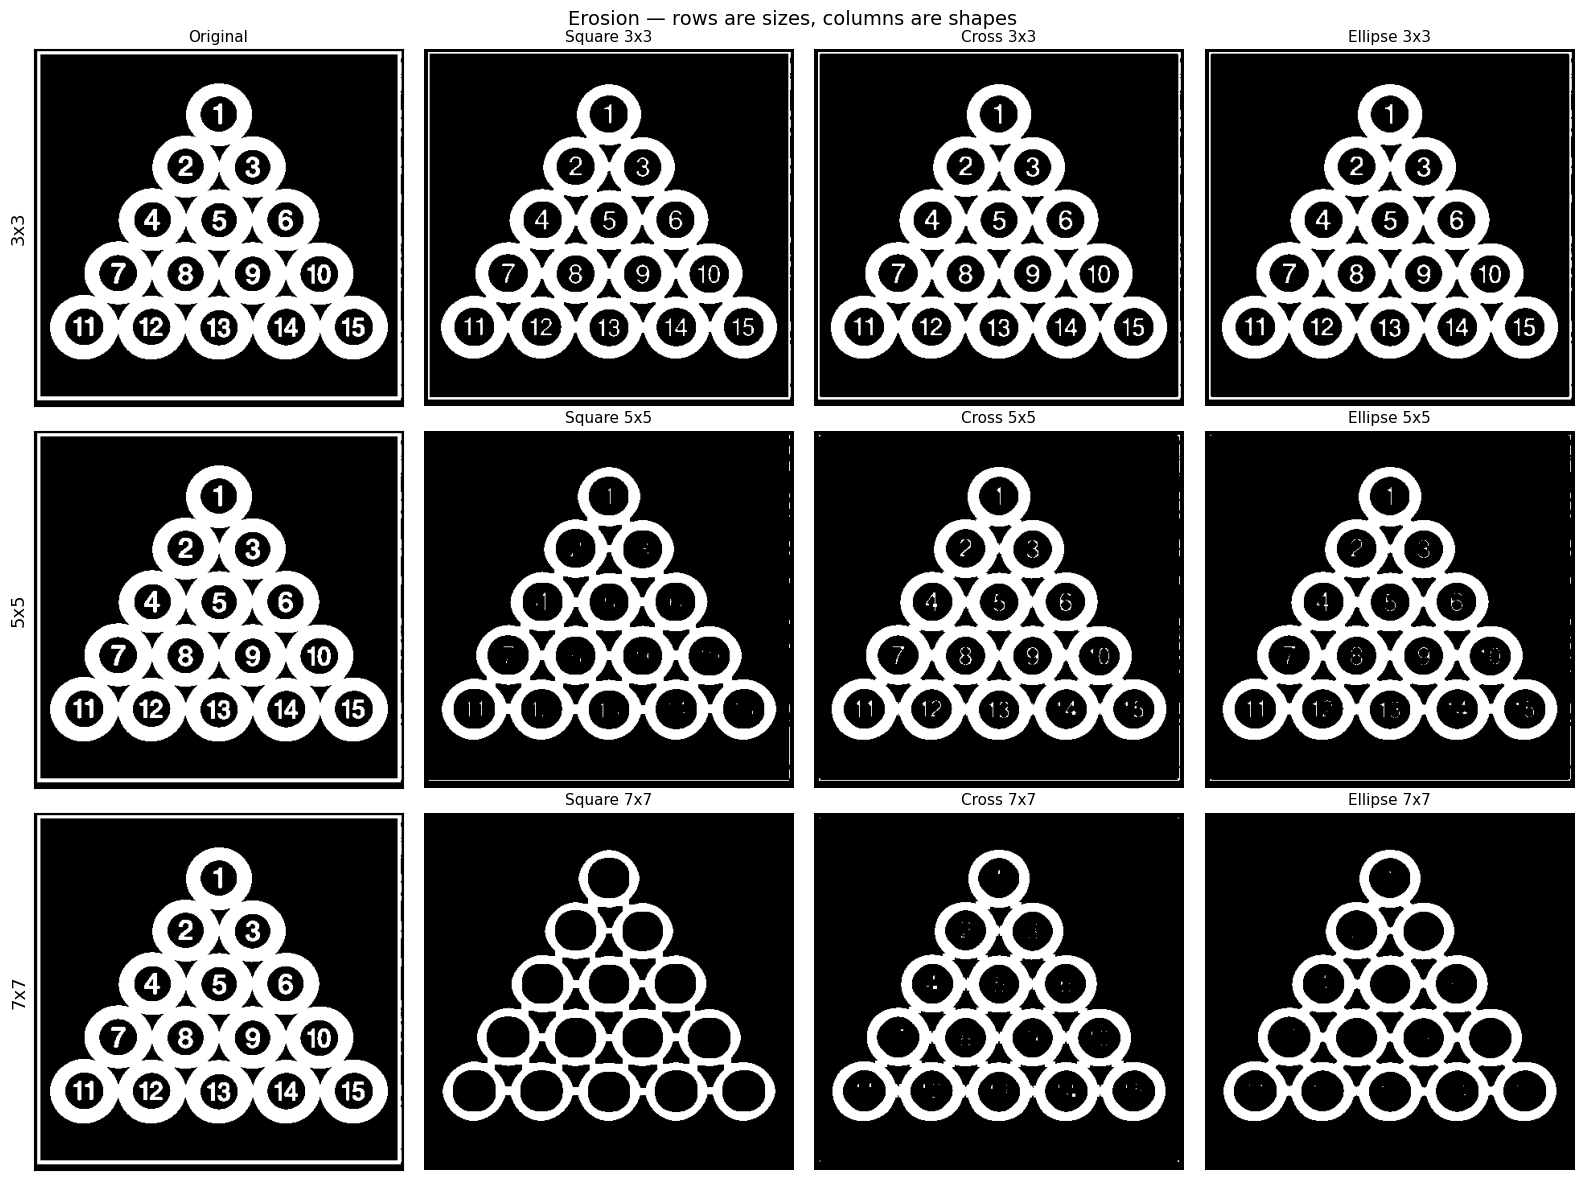

In [16]:
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for r, size in enumerate(sizes):
    axes[r, 0].imshow(binary, cmap='gray')
    axes[r, 0].set_title('Original' if r == 0 else '', fontsize=11)
    axes[r, 0].set_ylabel(f'{size}x{size}', fontsize=13)
    axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
    for c, (name, flag) in enumerate(shapes, start=1):
        s = cv2.getStructuringElement(flag, (size, size))
        axes[r, c].imshow(cv2.erode(binary, s), cmap='gray')
        axes[r, c].set_title(f'{name.split()[0]} {size}x{size}', fontsize=11)
        axes[r, c].axis('off')
fig.suptitle('Erosion — rows are sizes, columns are shapes', fontsize=14)
plt.tight_layout()
plt.savefig('output/lab9_task2_erosion.png', dpi=110, bbox_inches='tight')
plt.show()

## 2.2 Dilation with every shape and size

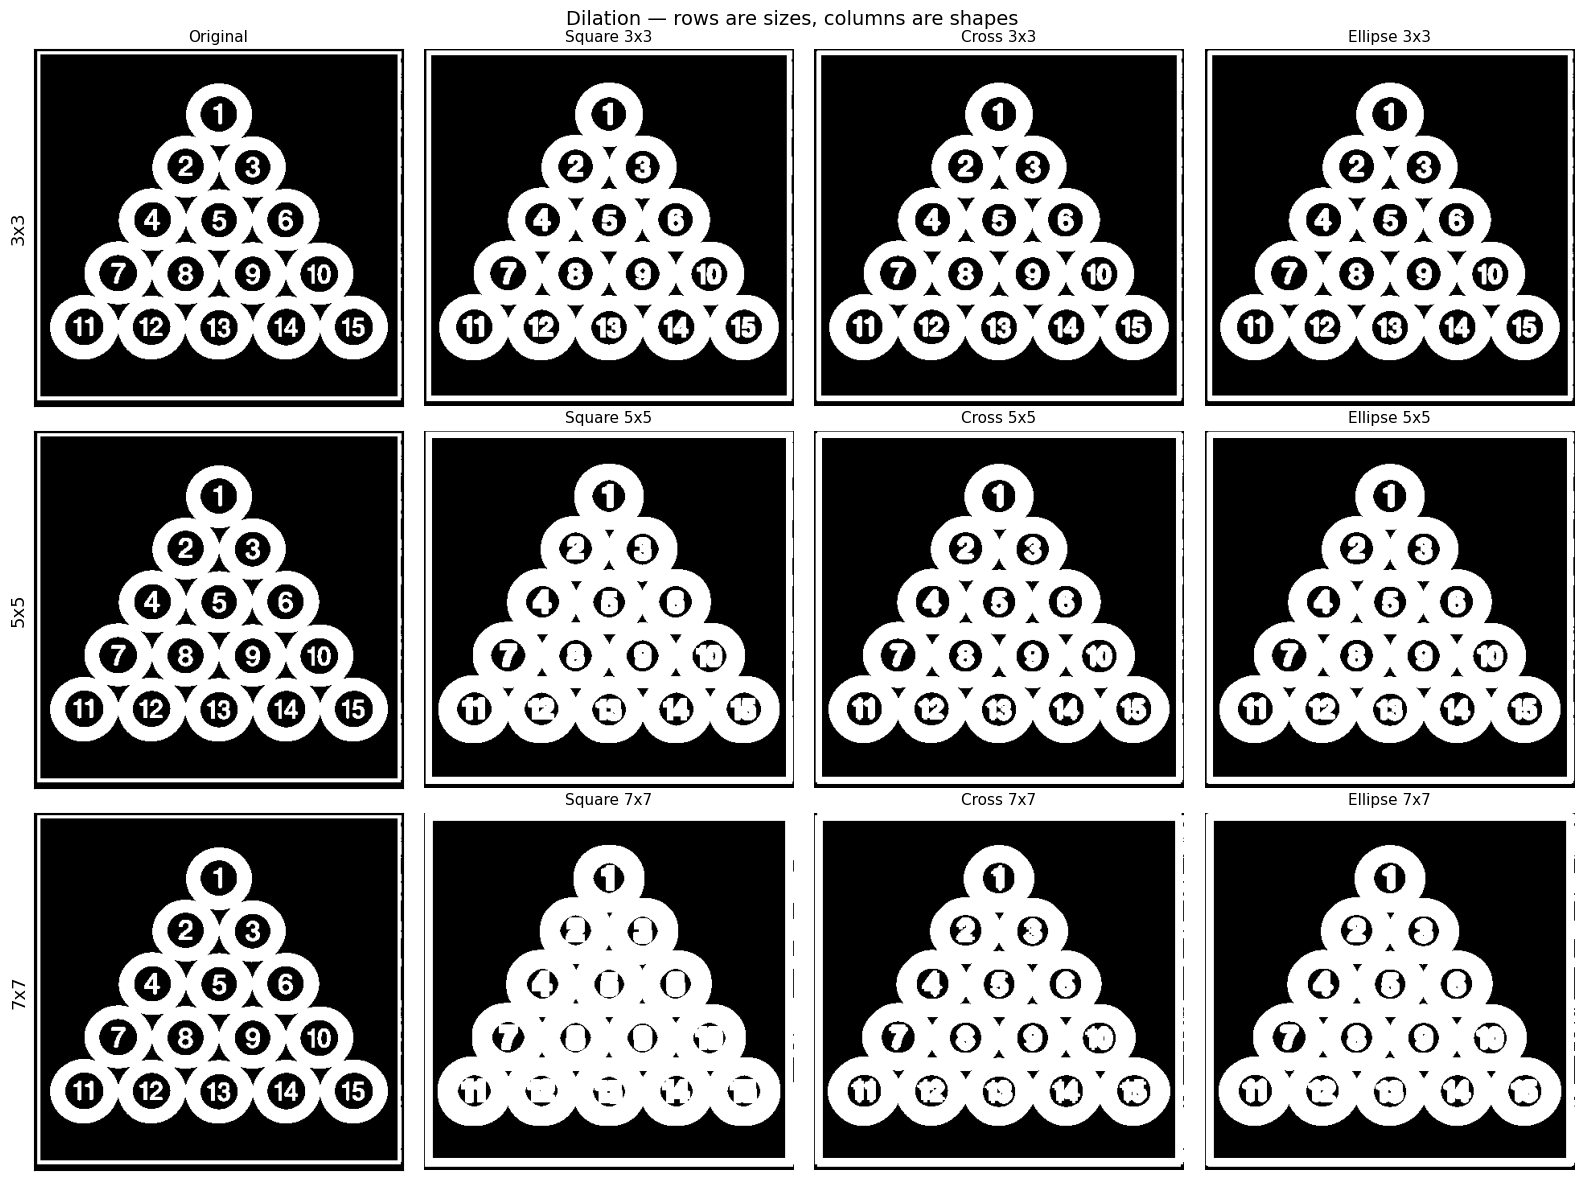

In [17]:
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for r, size in enumerate(sizes):
    axes[r, 0].imshow(binary, cmap='gray')
    axes[r, 0].set_title('Original' if r == 0 else '', fontsize=11)
    axes[r, 0].set_ylabel(f'{size}x{size}', fontsize=13)
    axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
    for c, (name, flag) in enumerate(shapes, start=1):
        s = cv2.getStructuringElement(flag, (size, size))
        axes[r, c].imshow(cv2.dilate(binary, s), cmap='gray')
        axes[r, c].set_title(f'{name.split()[0]} {size}x{size}', fontsize=11)
        axes[r, c].axis('off')
fig.suptitle('Dilation — rows are sizes, columns are shapes', fontsize=14)
plt.tight_layout()
plt.savefig('output/lab9_task2_dilation.png', dpi=110, bbox_inches='tight')
plt.show()

## 2.3 The comparison as numbers

The visual differences between the shapes are subtle, so the areas settle the question.

In [18]:
print(f"{'size':<7}{'shape':<12}{'pixels':>8}{'after erosion':>16}{'after dilation':>17}")
print("-" * 62)
print(f"{'—':<7}{'original':<12}{'—':>8}{white_pct(binary):>15.2f}%{white_pct(binary):>16.2f}%")
rows = []
for size in sizes:
    for name, flag in shapes:
        s = cv2.getStructuringElement(flag, (size, size))
        e = white_pct(cv2.erode(binary, s))
        d = white_pct(cv2.dilate(binary, s))
        rows.append((size, name.split()[0], int(s.sum()), e, d))
        print(f"{f'{size}x{size}':<7}{name.split()[0]:<12}{int(s.sum()):>8}"
              f"{e:>15.2f}%{d:>16.2f}%")

size   shape         pixels   after erosion   after dilation
--------------------------------------------------------------
—      original           —          31.85%           31.85%
3x3    Square             9          25.87%           37.70%
3x3    Cross              5          27.08%           36.57%
3x3    Ellipse            5          27.08%           36.57%
5x5    Square            25          19.98%           43.20%
5x5    Cross              9          22.38%           41.09%
5x5    Ellipse           17          21.40%           41.92%
7x7    Square            49          16.20%           48.24%
7x7    Cross             13          19.44%           45.33%
7x7    Ellipse           33          18.45%           46.21%


correlation between element pixel count and remaining area after erosion: -0.8652


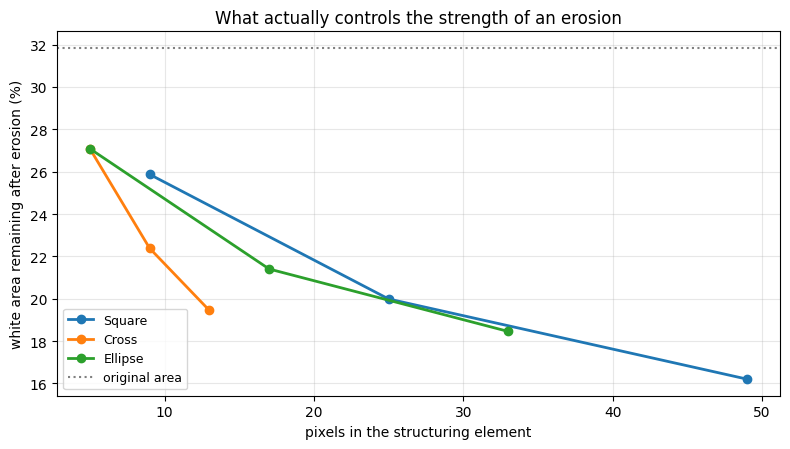

In [19]:
# does the amount removed follow the pixel count of the element?
px = [r[2] for r in rows]
er = [r[3] for r in rows]
print("correlation between element pixel count and remaining area after erosion:",
      round(float(np.corrcoef(px, er)[0, 1]), 4))

plt.figure(figsize=(8, 4.6))
for name in ['Square', 'Cross', 'Ellipse']:
    sel = [(r[2], r[3]) for r in rows if r[1] == name]
    plt.plot([p for p, _ in sel], [a for _, a in sel], 'o-', linewidth=2, label=name)
plt.axhline(white_pct(binary), color='grey', linestyle=':', label='original area')
plt.xlabel('pixels in the structuring element')
plt.ylabel('white area remaining after erosion (%)')
plt.title('What actually controls the strength of an erosion')
plt.legend(fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2.4 Comparison of the results

**Size is the dominant factor.** Going from 3x3 to 7x7 changes the remaining area far more than
switching shapes at a fixed size does. A larger element must fit inside a larger part of the
object, so more of the boundary fails the test and is removed.

**Within a size, the ranking follows the pixel count, not the name.** At 7x7 the square holds
49 pixels and leaves 16.20% of the image white; the ellipse holds 33 and leaves 18.45%; the
cross holds 13 and leaves 19.44%. The same ordering holds at 5x5 and at 3x3 — at every size,
without exception, more pixels in the element means less area left behind. The square is the
most aggressive shape simply because it is the largest, and the cross the gentlest because it
is the smallest.

Across all nine combinations together the correlation is −0.87 rather than −1. The looseness
comes from mixing sizes: a 5x5 square (25 px) and a 7x7 ellipse (33 px) have similar pixel
counts but reach different distances from the centre, and reach matters as well as count. The
relationship is exact within a size and approximate across sizes.

**The shape still matters for what the result looks like.** The square erodes equally in all
directions including the diagonals, so round objects acquire slightly flattened, polygonal
edges. The cross reaches only along the two axes, so diagonal boundaries are barely touched and
corners survive that a square would have removed. The ellipse is the compromise, and for round
objects like these balls it is the natural choice because it preserves their curvature instead
of imposing a different geometry on them.

**A practical consequence.** Comparing a 7x7 square with a 7x7 cross is not comparing two
shapes at equal strength — it is comparing a 49-pixel element with a 13-pixel one. To isolate
the effect of shape alone, elements of similar pixel count should be compared, which is why the
plot above is drawn against pixel count rather than against nominal size.

---
## Conclusion

**Polarity comes before everything else.** OpenCV's morphological operations shrink white and
grow white, with no notion of which part of the picture is the subject. The balls in this image
are dark on a light background, so the plain `THRESH_BINARY` used in the lab notebook makes the
*background* the object — 68.2% of the image — and an erosion then appears to make the balls
larger. `THRESH_BINARY_INV` fixes it. The duality `erode(A) = not(dilate(not(A)))` was verified
directly, and it is precisely why the mistake produces a result that looks like the opposite
operation rather than an error.

**Erosion and dilation change size; opening and closing change structure.** At 7x7 erosion
removed about 13% of the image area and dilation added about 14%, while opening and closing
moved the total by only a few percent. Combining the two operations cancels the size change and
leaves the structural effect behind, which is the entire reason for using them.

**Opening is a size filter, and the measurement was exact.** At 7x7 the largest connected
component — the mass of balls — kept **100.0%** of its area, while the small objects, the
printed digits, were cut to **4.5%** of theirs. Below the threshold set by the structuring
element objects are deleted; above it they are untouched.

**Closing fills holes, until the element outgrows the problem.** The enclosed hole area fell
steadily from 31,320 pixels to 17,112 as the element grew to 11x11. At 13x13 it jumped to
35,842 — above the original — because the element had become wide enough to bridge the gaps
*between* neighbouring balls, and the triangular spaces between the now-merged balls turned into
new enclosed holes. The largest single hole grew from 3,230 pixels to 24,546, which identifies
the mechanism unambiguously. The structuring element has to be chosen against both the features
to be removed and the spacing between objects.

**The shape of a structuring element matters less than its area.** The ranking of square,
ellipse and cross at any given size follows their pixel counts — 49, 33 and 13 at 7x7 — without
exception at any of the three sizes tested. The square is the harshest because it is the
largest, not because it is square. Across sizes the relationship loosens to a correlation of
−0.87, because how far an element reaches from its centre matters alongside how many pixels it
holds. Shape still governs the
*geometry* of the result: squares flatten curved boundaries, crosses spare diagonals, and the
ellipse preserves roundness, which is why it suits an image of balls. But a comparison of a 7x7
square against a 7x7 cross is a comparison of strengths, not of shapes.

---

### Resources
- OpenCV morphological transformations:
  https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html
- `cv2.getStructuringElement`:
  https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html